In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(7)
rng = np.random.default_rng(7)

## 1. Synthetic signal

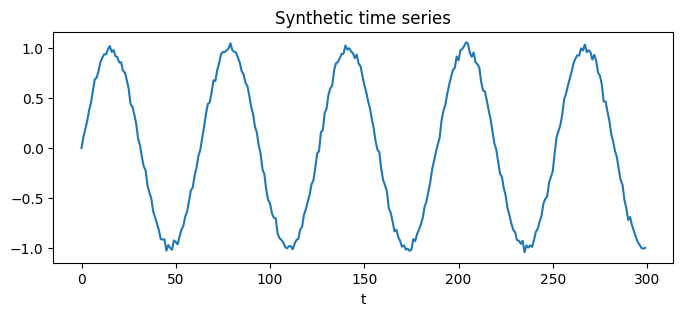

In [2]:
t = np.arange(300)
signal = np.sin(0.1 * t) + rng.normal(0, 0.03, size=t.shape)   # sine + a little noise

plt.figure(figsize=(8, 3)); plt.plot(signal)
plt.title("Synthetic time series"); plt.xlabel("t"); plt.show()

## 2. Sliding-window dataset

In [3]:
WINDOW = 10

def make_windows(series, window):
    X = np.stack([series[i:i + window] for i in range(len(series) - window)])
    y = series[window:]
    return X[..., None].astype("float32"), y.astype("float32")   # shape (n, window, 1)

X, y = make_windows(signal, WINDOW)
cut = int(0.8 * len(X))
X_tr, X_te, y_tr, y_te = X[:cut], X[cut:], y[:cut], y[cut:]
print(X_tr.shape, X_te.shape)

(232, 10, 1) (58, 10, 1)


## 3. Models

In [4]:
def make_ffnn():
    return models.Sequential([
        layers.Input(shape=(WINDOW, 1)),
        layers.Flatten(),
        layers.Dense(32, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(1),
    ])

def make_birnn():
    return models.Sequential([
        layers.Input(shape=(WINDOW, 1)),
        layers.Bidirectional(layers.SimpleRNN(32)),
        layers.Dense(16, activation="relu"),
        layers.Dense(1),
    ])

nets = {"Feed-forward": make_ffnn(), "BiRNN": make_birnn()}
for net in nets.values():
    net.compile(optimizer="adam", loss="mse")

## 4. Train and score

In [5]:
fits, scores = {}, {}
for name, net in nets.items():
    fits[name] = net.fit(X_tr, y_tr, epochs=30, batch_size=16, validation_split=0.1, verbose=0)
    scores[name] = net.evaluate(X_te, y_te, verbose=0)
    print(f"{name:13s} test MSE = {scores[name]:.5f}")

Feed-forward  test MSE = 0.00178
BiRNN         test MSE = 0.00250


## 5. Plots

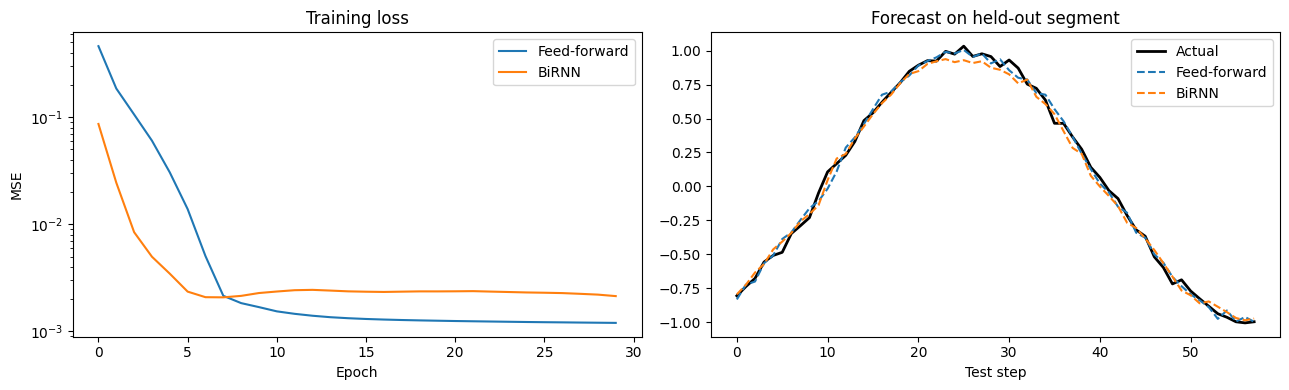

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
for name, h in fits.items():
    ax1.plot(h.history["loss"], label=name)
ax1.set(xlabel="Epoch", ylabel="MSE", title="Training loss", yscale="log"); ax1.legend()

ax2.plot(y_te, "k", label="Actual", linewidth=2)
for name, net in nets.items():
    ax2.plot(net.predict(X_te, verbose=0).ravel(), "--", label=name)
ax2.set(xlabel="Test step", title="Forecast on held-out segment"); ax2.legend()
plt.tight_layout(); plt.show()